In [1]:
import numpy as np # to handle matrix and data operation
import pandas as pd # to read csv and handle dataframe

import torch # to load pytorch library
import torch.nn as nn # to load pytorch library
import torch.nn.functional as F # to load pytorch function
import torch.utils.data # to load data processor
from torch.autograd import Variable # pytorch data type
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

<class 'pandas.DataFrame'>
RangeIndex: 59999 entries, 0 to 59998
Columns: 785 entries, 5 to 0.617
dtypes: int64(785)
memory usage: 359.3 MB
<class 'pandas.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Columns: 785 entries, 7 to 0.667
dtypes: int64(785)
memory usage: 59.9 MB


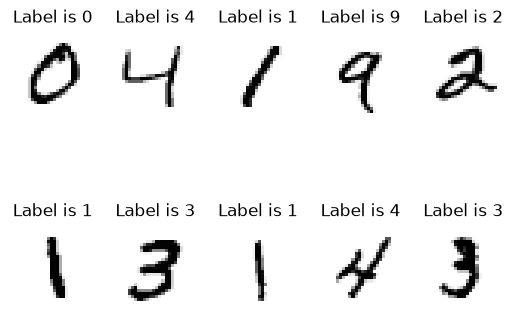

In [2]:
train = pd.read_csv('mnist_data/mnist_train.csv')
test = pd.read_csv('mnist_data/mnist_test.csv')
train.info()
test.info()

# split image and label
train_label = train.iloc[:, 0].values
train_img = train.iloc[:, 1:]
test_label = test.iloc[:, 0].values
test_img = test.iloc[:, 1:]
# check the dataset of one example
count=1
for a in range (10):
    imarray = train_img.iloc[a, :].values.reshape(28,28)
    plt.subplot(2,5,count)
    plt.subplots_adjust(hspace=0.1)
    count += 1
    plt.axis('off')
    plt.title("Label is " + str(train_label[a]))
    plt.imshow(imarray, cmap='Greys', interpolation='None')

In [3]:
# reshape to be [samples][pixels][width][height]
train_img = train_img.values.reshape(-1,1,28,28)
test_img = test_img.values.reshape(-1,1,28,28)
train_img = train_img / 255.0
test_img = test_img / 255.0
# normalize inputs from 0-255 to 0-1
print(train_img.shape)
print(train_label.shape)
print(test_img.shape)
print(test_label.shape)

BATCH_SIZE = 1000

# create feature and targets tensor for training set.
torch_X_train = torch.from_numpy(train_img).float()
torch_y_train = torch.from_numpy(train_label)
# create feature and targets tensor for testing set.
torch_X_test = torch.from_numpy(test_img).float()
torch_y_test = torch.from_numpy(test_label)
# Pytorch train and test sets
train = torch.utils.data.TensorDataset(torch_X_train,torch_y_train)
test = torch.utils.data.TensorDataset(torch_X_test,torch_y_test)

# data loader
train_loader = torch.utils.data.DataLoader(train, batch_size = BATCH_SIZE, shuffle = False, num_workers=0)
test_loader = torch.utils.data.DataLoader(test, batch_size = BATCH_SIZE, shuffle = False, num_workers=0)

(59999, 1, 28, 28)
(59999,)
(9999, 1, 28, 28)
(9999,)


C:\Users\Hamidur\AppData\Local\Temp\ipykernel_34136\4232363624.py:16: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  torch_y_train = torch.from_numpy(train_label)


In [4]:
# Defining the network (LeNet-5)
class LeNet5(nn.Module):
    #This defines the structure of the NN.
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1, padding=2)
        self.act1 = nn.ReLU()
        self.maxpool1 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1, padding=0)
        self.act2 = nn.ReLU()
        self.maxpool2 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.fc1 = nn.Linear(in_features=400, out_features=120)
        self.act3 = nn.ReLU()
        self.fc2 = nn.Linear(in_features=120, out_features=84)
        self.act4 = nn.ReLU()
        self.fc3 = nn.Linear(in_features=84, out_features=10)

    def forward(self, x):
        #Convolutional Layer/Pooling Layer/Activation
        x = self.conv1(x)
        x = self.act1(x)
        x = self.maxpool1(x)
        #Convolutional Layer/Dropout/Pooling Layer/Activation
        x = self.conv2(x)
        x = self.act2(x)
        x = self.maxpool2(x)
        x = x.view(-1, 400)
        #Fully Connected Layer/Activation
        x = self.fc1(x)
        x = self.act3(x)
        #Fully Connected Layer/Activation
        x = self.fc2(x)
        x = self.act4(x)

        return self.fc3(x)

criterion = nn.CrossEntropyLoss()
if torch.cuda.is_available():
    criterion = criterion.cuda()


In [5]:
def train(model, epoch, optimizer):
    model.train()
    epoch_loss = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        if torch.cuda.is_available():
            data, target = data.cuda(), target.cuda()
        #Variables in Pytorch are differenciable.
        data, target = Variable(data), Variable(target)
        #This will zero out the gradients for this batch.
        optimizer.zero_grad()
        output = model(data)
        # Calculate the loss The negative log likelihood loss. It is useful to train a classification problem with C classes.
        loss = criterion(output, target)
        #dloss/dx for every Variable
        loss.backward()
        #to do a one-step update on our parameter.
        optimizer.step()
        epoch_loss += loss.item()
    #Print out the loss periodically.
    avg_loss = epoch_loss / len(train_loader)
    print("===> Epoch {} Complete: Training loss: {:.4f}".format(epoch, avg_loss))
    return avg_loss

In [6]:
def train_accuracy(model, epoch):
    model.eval()
    correct = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        if torch.cuda.is_available():
            data, target = data.cuda(), target.cuda()
        data, target = Variable(data), Variable(target)
        with torch.no_grad():
            output = model(data)
        _, predicted = torch.max(output.data, 1) # get the index of the max log-probability
        correct += (predicted == target).sum().item()
    avg_accuracy = correct / len(train_loader.dataset)
    print("===> Epoch {} Complete: Training accuracy: {:.4f}%".format(epoch, 100. * avg_accuracy))
    return avg_accuracy

In [7]:
def test(model, epoch):
    model.eval()
    correct = 0
    for batch_idx, (data, target) in enumerate(test_loader):
        if torch.cuda.is_available():
            data, target = data.cuda(), target.cuda()
            
        data, target = Variable(data), Variable(target)
        with torch.no_grad():
            output = model(data)
        _, predicted = torch.max(output.data, 1) # get the index of the max log-probability
        correct += (predicted == target).sum().item()
    avg_accuracy = correct / len(test_loader.dataset)
    print("===> Epoch {} Complete: Testing accuracy: {:.4f}%".format(epoch, 100. * avg_accuracy))
    return avg_accuracy

In [8]:
def checkpoint(model, epoch):
    model_out_path = "Training_epoch_{}.pth".format(epoch)
    torch.save(model.state_dict(), model_out_path)
    print("Checkpoint saved to {}".format(model_out_path))

In [9]:
model = LeNet5()

if torch.cuda.is_available():
    model.cuda() # set model to use GPU if available, defaults to CPU


optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.5)

**Task 1:**  A full loop that records the training loss and testing accuracy

In [10]:
train_losses = []
train_correct = []
test_correct = []
for epoch in range(1, 51, 1):
    # Trainining loss
    train_losses.append(train(model, epoch, optimizer))
    # Training accuracy
    train_correct.append(train_accuracy(model, epoch))
    # Testing accuracy
    test_correct.append(test(model, epoch))
    if epoch % 10 == 0:
        # Model checkpointing
        checkpoint(model, epoch)

# keep the results of the original run (lr=0.01) for the comparison in Task 4
orig_train_losses, orig_train_correct, orig_test_correct = list(train_losses), list(train_correct), list(test_correct)

===> Epoch 1 Complete: Training loss: 2.3009


===> Epoch 1 Complete: Training accuracy: 10.4652%
===> Epoch 1 Complete: Testing accuracy: 10.2710%


===> Epoch 2 Complete: Training loss: 2.2952


===> Epoch 2 Complete: Training accuracy: 12.2652%
===> Epoch 2 Complete: Testing accuracy: 12.1512%


===> Epoch 3 Complete: Training loss: 2.2889


===> Epoch 3 Complete: Training accuracy: 17.7470%
===> Epoch 3 Complete: Testing accuracy: 18.4018%


... (91 outputs left out)

===> Epoch 49 Complete: Training loss: 0.0955


===> Epoch 49 Complete: Training accuracy: 97.1383%
===> Epoch 49 Complete: Testing accuracy: 97.3497%


===> Epoch 50 Complete: Training loss: 0.0938


===> Epoch 50 Complete: Training accuracy: 97.1850%
===> Epoch 50 Complete: Testing accuracy: 97.3497%
Checkpoint saved to Training_epoch_50.pth


**Task 2.** Plot the training loss and testing accuracy VS epoches

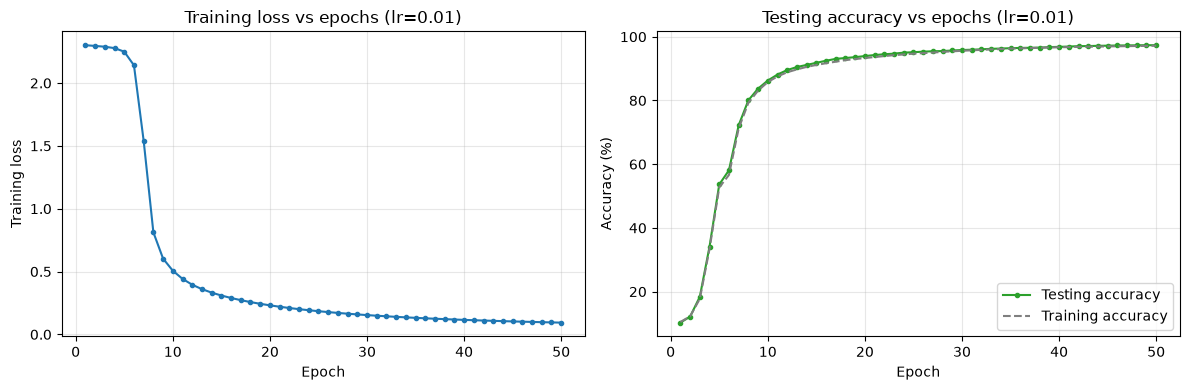

Final training loss: 0.0938, final testing accuracy: 97.35%


In [11]:
epochs = range(1, len(train_losses) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, train_losses, marker='o', markersize=3)
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Training loss'); ax1.set_title('Training loss vs epochs (lr=0.01)')
ax1.grid(alpha=0.3)
ax2.plot(epochs, [100 * a for a in test_correct], marker='o', markersize=3, color='tab:green', label='Testing accuracy')
ax2.plot(epochs, [100 * a for a in train_correct], linestyle='--', color='tab:gray', label='Training accuracy')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)'); ax2.set_title('Testing accuracy vs epochs (lr=0.01)')
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('task2_loss_accuracy.png', dpi=150)
plt.show()
print('Final training loss: {:.4f}, final testing accuracy: {:.2f}%'.format(train_losses[-1], 100 * test_correct[-1]))

**Task 3.** load pre-trained model and visualize the prediction on the testing samples.

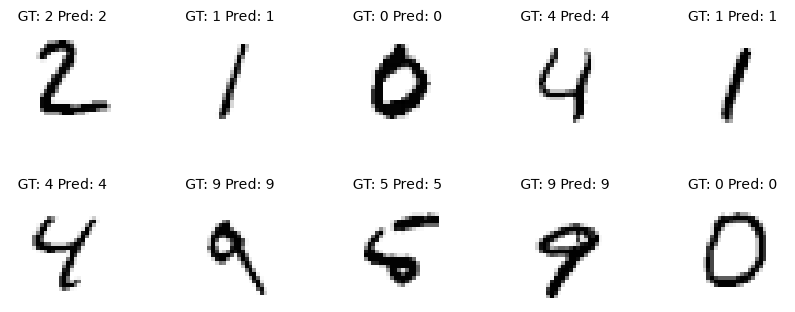

In [12]:
model_name = 'Training_epoch_50.pth'
model.load_state_dict(torch.load(model_name, map_location=lambda storage, loc: storage)) # load the trained model
count=1
model.eval()
plt.figure(figsize=(10, 4))
for a in range (10):
    imarray = test_img[a].reshape(1,1,28,28)
    data = torch.from_numpy(imarray).float()
    if torch.cuda.is_available():
        data = data.cuda()

    # Fill here:
    # Input the image to the loaded model
    with torch.no_grad():
        output = model(data)
    # Get the predicted class labels using argmax or max on the model output
    predicted = torch.argmax(output, dim=1)

    plt.subplot(2,5,count)
    plt.subplots_adjust(hspace=0.2, wspace = 0.6)
    count += 1
    plt.axis('off')
    plt.title('GT: ' + str(test_label[a]) + ' Pred: ' + str(predicted.item()), fontsize=10)
    plt.imshow(imarray[0,0,:,:], cmap='Greys', interpolation='None')
plt.savefig('task3_predictions.png', dpi=150, bbox_inches='tight')

**Task 4.** Change the learning rate and retrain the model again, plot the new training loss and original training loss in one figure and explain your discovery.

In [13]:
model2 = LeNet5() # initialize a new model
if torch.cuda.is_available():
    model2.cuda() # Move the model to GPU if available
NEW_LR = 0.1
optimizer2 = torch.optim.SGD(model2.parameters(), lr=NEW_LR, momentum=0.5) # Fill a new optimizer

In [14]:
train_losses = []
train_correct = []
test_correct = []

for epoch in range(1, 51, 1):
    # Training loss
    train_losses.append(train(model2, epoch, optimizer2))
    # Training accuracy
    train_correct.append(train_accuracy(model2, epoch))
    # Test accuracy
    test_correct.append(test(model2, epoch))

===> Epoch 1 Complete: Training loss: 2.2543


===> Epoch 1 Complete: Training accuracy: 32.9939%
===> Epoch 1 Complete: Testing accuracy: 33.0633%


===> Epoch 2 Complete: Training loss: 1.6016


===> Epoch 2 Complete: Training accuracy: 83.3297%
===> Epoch 2 Complete: Testing accuracy: 84.2384%


===> Epoch 3 Complete: Training loss: 0.2821


===> Epoch 3 Complete: Training accuracy: 94.3999%
===> Epoch 3 Complete: Testing accuracy: 94.7795%


... (95 outputs left out)

===> Epoch 49 Complete: Training loss: 0.0090


===> Epoch 49 Complete: Training accuracy: 99.4717%
===> Epoch 49 Complete: Testing accuracy: 98.6799%


===> Epoch 50 Complete: Training loss: 0.0086


===> Epoch 50 Complete: Training accuracy: 99.5200%
===> Epoch 50 Complete: Testing accuracy: 98.7099%


Plot accuracies and loss

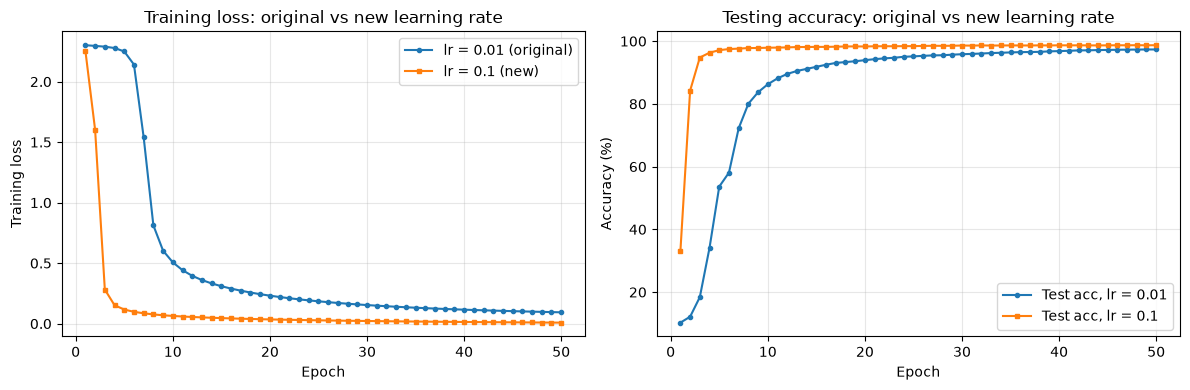

 lr=0.01: loss@1=2.3009 loss@10=0.5070 loss@50=0.0938 | test acc@10=86.26% test acc@50=97.35%
  lr=0.1: loss@1=2.2543 loss@10=0.0640 loss@50=0.0086 | test acc@10=97.91% test acc@50=98.71%


In [15]:
epochs = range(1, 51)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, orig_train_losses, marker='o', markersize=3, label='lr = 0.01 (original)')
ax1.plot(epochs, train_losses, marker='s', markersize=3, label='lr = {} (new)'.format(NEW_LR))
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Training loss'); ax1.set_title('Training loss: original vs new learning rate')
ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(epochs, [100 * a for a in orig_test_correct], marker='o', markersize=3, label='Test acc, lr = 0.01')
ax2.plot(epochs, [100 * a for a in test_correct], marker='s', markersize=3, label='Test acc, lr = {}'.format(NEW_LR))
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)'); ax2.set_title('Testing accuracy: original vs new learning rate')
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('task4_lr_comparison.png', dpi=150)
plt.show()
for name, l, te in [('lr=0.01', orig_train_losses, orig_test_correct), ('lr={}'.format(NEW_LR), train_losses, test_correct)]:
    print('{:>8}: loss@1={:.4f} loss@10={:.4f} loss@50={:.4f} | test acc@10={:.2f}% test acc@50={:.2f}%'.format(
        name, l[0], l[9], l[-1], 100 * te[9], 100 * te[-1]))

**Discovery (Task 4):** see the explanation in the report; summary printed above.